In [ ]:
%load_ext jupyter_black
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np

from src.analysis.avalanche_analysis import avalanches_from_activity
from src.utils.raster_plot import raster_plot
from src.models.branching_model.branching_network import (
    pif_aa_population,
    lam_of_h,
    params_for_distance,
    distance_to_criticality
)
from src.analysis.timescales import get_autocorrelation

The jupyter_black extension is already loaded. To reload it, use:
  %reload_ext jupyter_black
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


C:\Users\andre\OneDrive\Education\4_Tuebingen\Comp_Neuroscience\3_4_Lab_rotations\1_Anna_Levina_critical_networks\repository\src\models\branching_model\pif.py:280: UserWarning: spike probability exceeded p_max=0.99998; clipping
  A_t = step(A_t)


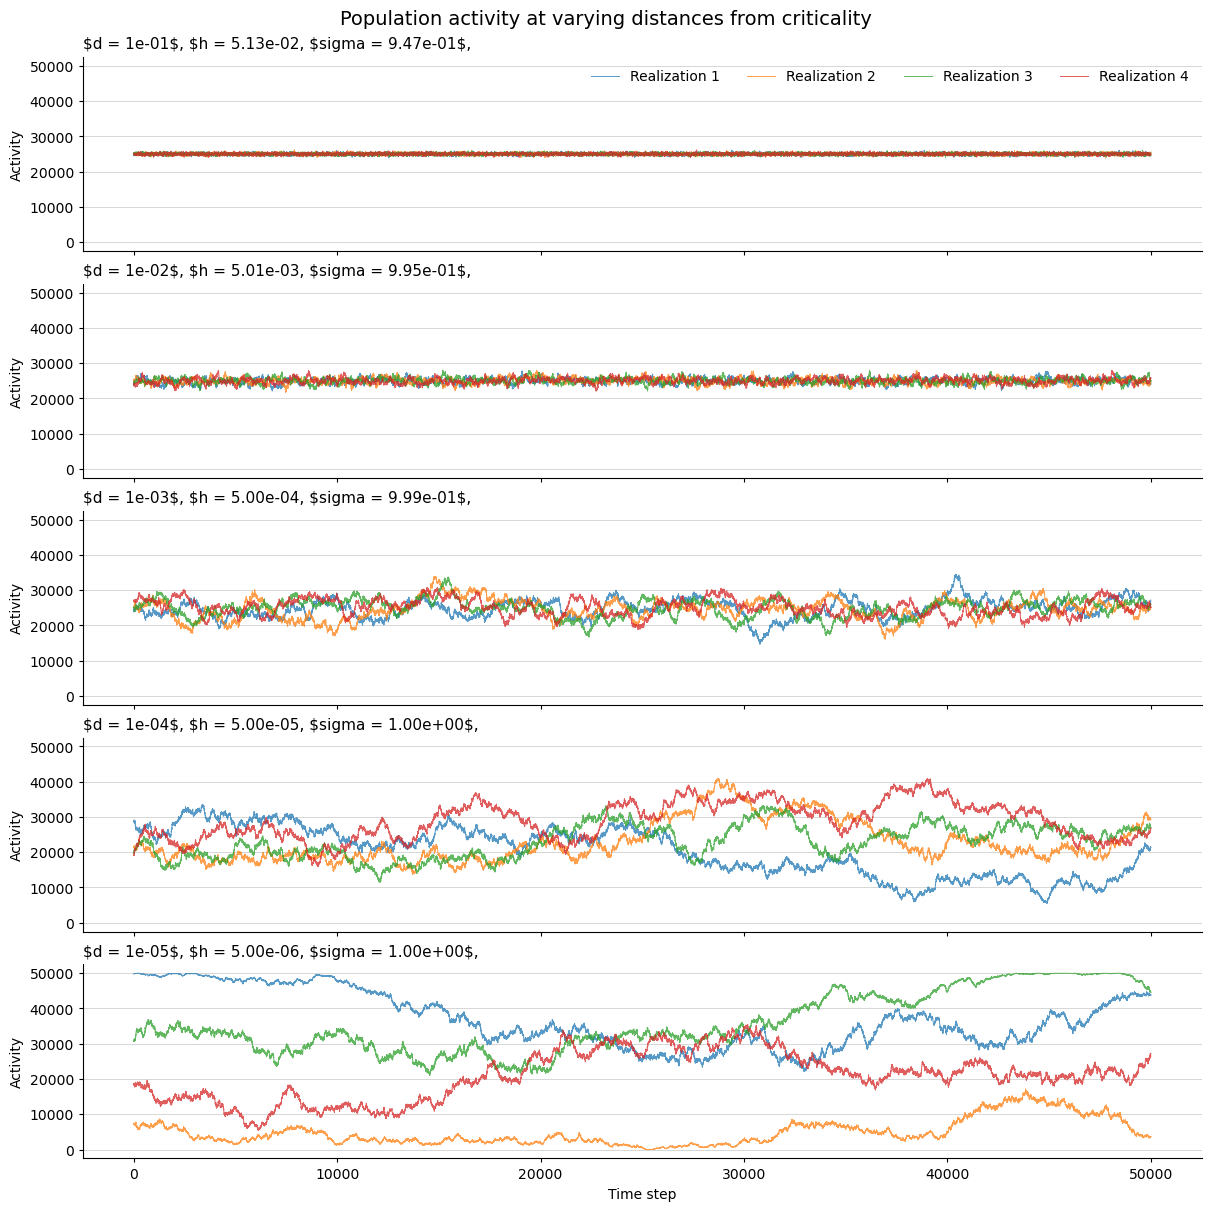

In [ ]:
N = int(5e4)
T = int(5e4)
R = 4

distances = [1e-1, 1e-2, 1e-3, 1e-4, 1e-5]
num_dist = len(distances)

fig, axes = plt.subplots(
    num_dist,
    1,
    figsize=(12, 2.4 * num_dist),
    sharex=True,
    sharey=True,
    layout="constrained",
)

for i, distance in enumerate(distances):
    sigma, h = params_for_distance(rate=0.5, distance=distance)

    A = pif_aa_population(
        N=N,
        sigma=sigma,
        T=T,
        h=h,
        R=R,
        A0="stationary",
        seed=321,
        return_raster=False,
        p_max=1 - 1 / N,
    )

    for j in range(R):
        axes[i].plot(
            A[j],
            linewidth=0.7,
            alpha=0.75,
            label=f"Realization {j + 1}" if i == 0 else None,
        )

    axes[i].set_title(
        rf"d = {distance:.0e}$, $h = {h:.4e}, $sigma = {sigma:.4e},",
        loc="left",
        fontsize=11,
        fontweight="medium",
    )
    axes[i].set_ylabel("Activity")
    axes[i].grid(axis="y", alpha=0.6, linewidth=0.6)
    axes[i].spines[["top", "right"]].set_visible(False)
    axes[i].tick_params(direction="out", length=3)

axes[-1].set_xlabel("Time step")
axes[0].legend(frameon=False, ncol=R, loc="upper right")

fig.suptitle(
    "Population activity at varying distances from criticality",
    fontsize=14,
    fontweight="medium",
)

plt.show()

C:\Users\andre\OneDrive\Education\4_Tuebingen\Comp_Neuroscience\3_4_Lab_rotations\1_Anna_Levina_critical_networks\repository\src\models\branching_model\pif.py:280: UserWarning: spike probability exceeded p_max=0.9998; clipping
  A_t = step(A_t)


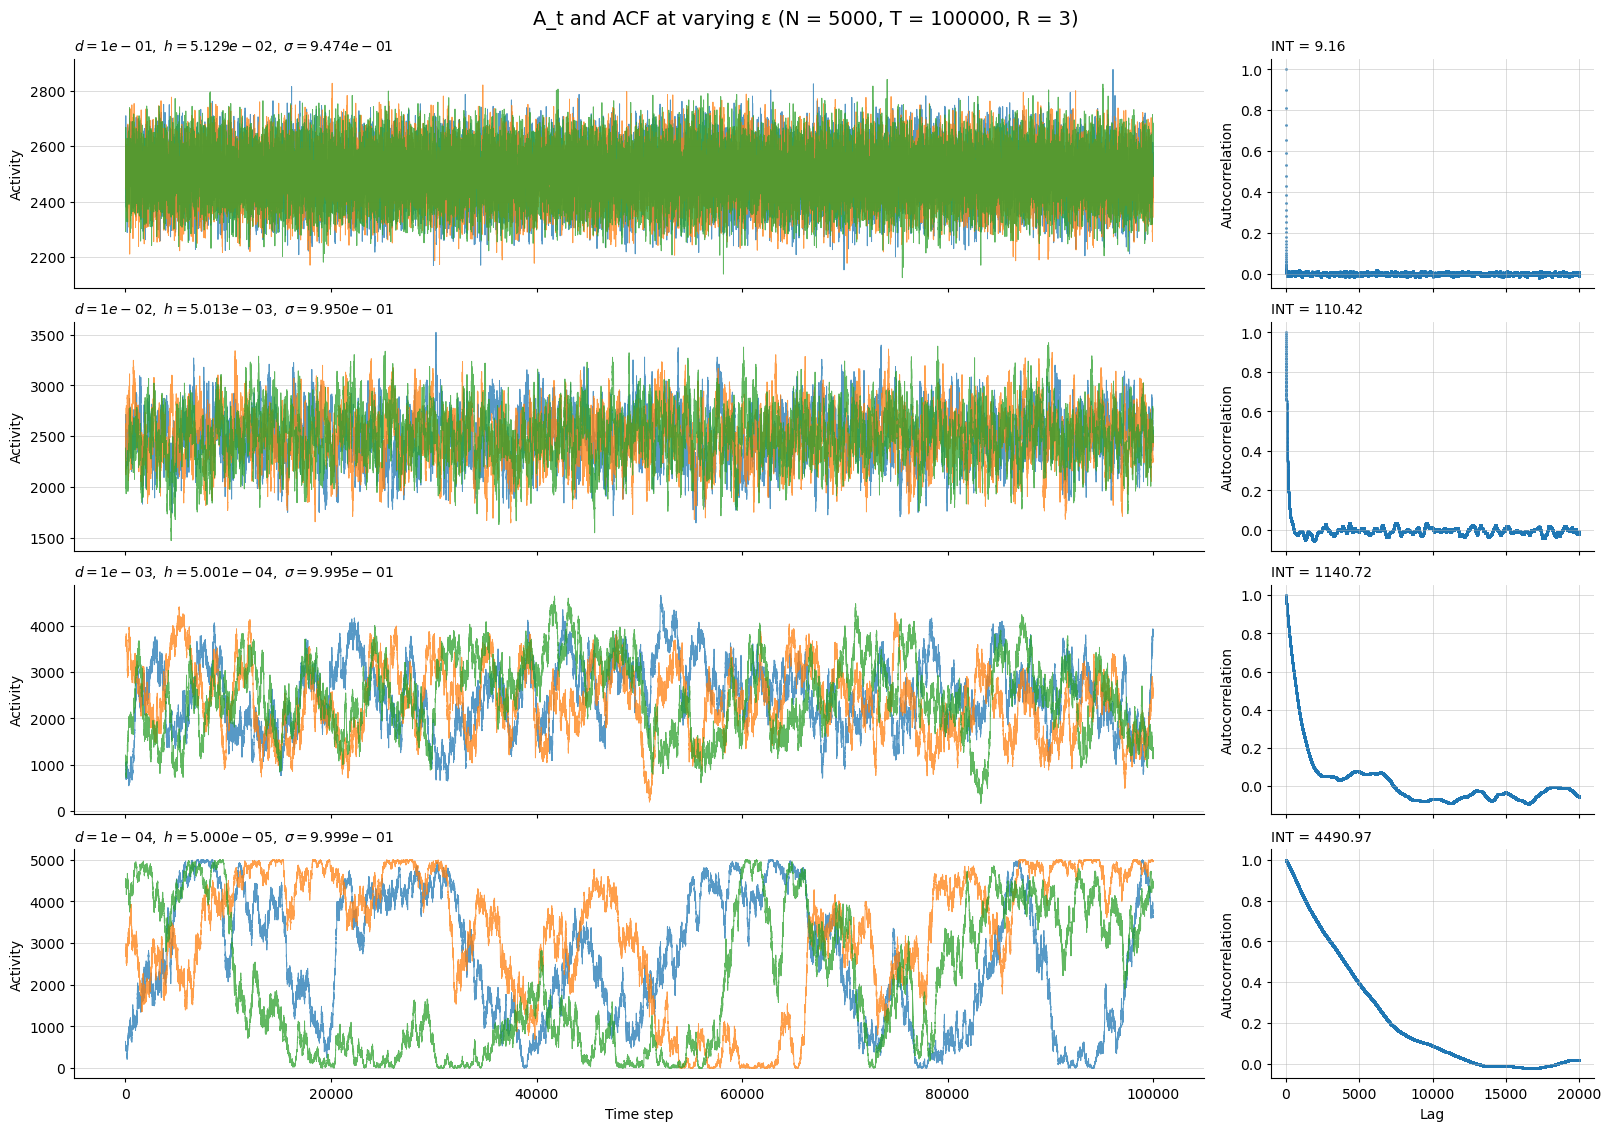

In [60]:
N = int(5e3)
T = int(1e5)
R = 3

distances = [1e-1, 1e-2, 1e-3, 1e-4]
num_dist = len(distances)

fig, axes = plt.subplots(
    num_dist,
    2,
    figsize=(16, 2.8 * num_dist),
    gridspec_kw={"width_ratios": [3.5, 1]},
    sharex="col",
    layout="constrained",
)

for i, distance in enumerate(distances):
    sigma, h = params_for_distance(rate=0.5, distance=distance)

    A = pif_aa_population(
        N=N,
        sigma=sigma,
        T=T,
        h=h,
        R=R,
        A0="stationary",
        seed=321,
        return_raster=False,
        p_max=1 - 1 / N,
    )

    # Left: population activity over time
    for j in range(R):
        axes[i, 0].plot(
            A[j],
            linewidth=0.7,
            alpha=0.75,
            label=f"Realization {j + 1}" if i == 0 else None,
        )
    axes[i, 0].set_ylabel("Activity")
    axes[i, 0].grid(axis="y", alpha=0.5, linewidth=0.6)
    axes[i, 0].spines[["top", "right"]].set_visible(False)
    axes[i, 0].tick_params(direction="out", length=3)

    # Right: autocorrelation of the same realization
    max_lag = int(T / 5)
    autocorr, lags, [INT, INT_01, acw_0, acw_01] = get_autocorrelation(A, max_lag)

    axes[i, 1].scatter(
        np.arange(len(autocorr)),
        autocorr,
        s=1,
        alpha=0.8,
    )
    axes[i, 1].set_ylabel("Autocorrelation")
    axes[i, 1].grid(alpha=0.5, linewidth=0.6)
    axes[i, 1].spines[["top", "right"]].set_visible(False)
    axes[i, 1].tick_params(direction="out", length=3)
    axes[i, 1].set_yscale("linear")
    axes[i, 1].set_xscale("linear")

    axes[i, 1].set_title(
        rf"INT = {INT:.2f}",
        loc="left",
        fontsize=10,
    )

    axes[i, 0].set_title(
        rf"$d = {distance:.0e},\ h = {h:.3e},\ " rf"\sigma = {sigma:.3e}$",
        loc="left",
        fontsize=10,
    )

axes[-1, 0].set_xlabel("Time step")
axes[-1, 1].set_xlabel("Lag")

fig.suptitle(
    f"A_t and ACF at varying ε (N = {N}, T = {T}, R = {R})",
    fontsize=14,
)

plt.show()

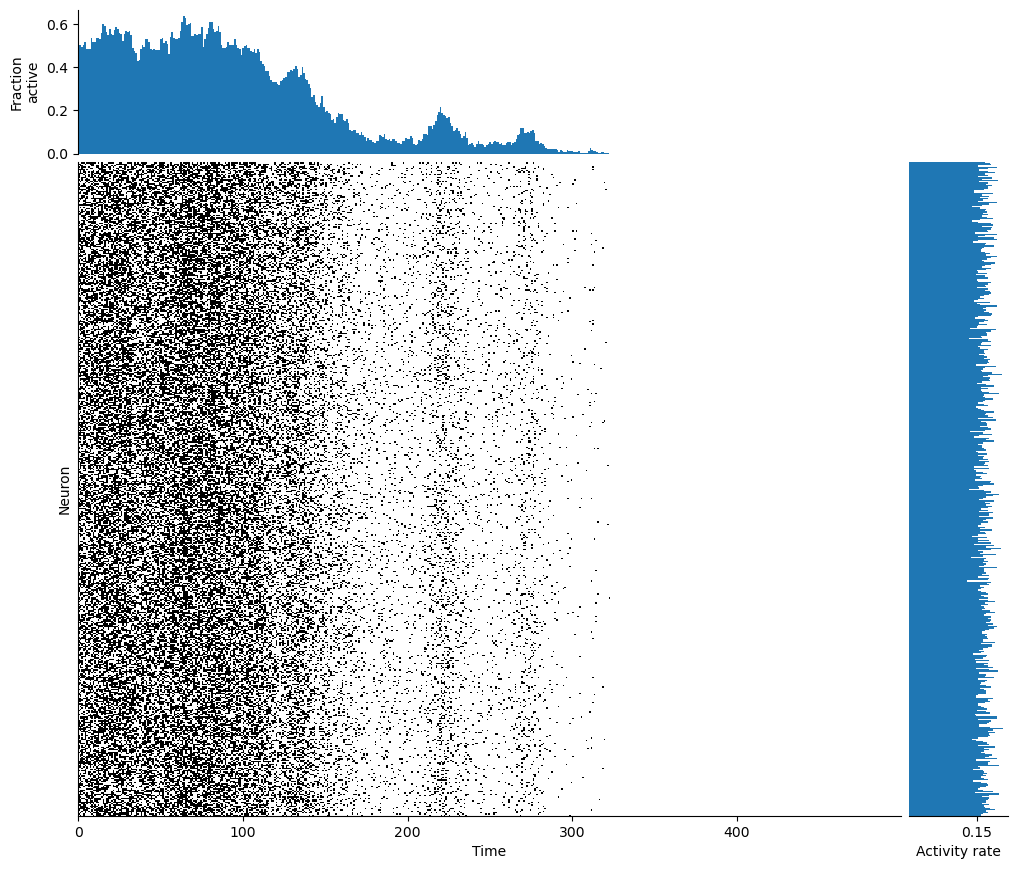

In [16]:
### no input activit, just perfectly critical behaviour dying out.

N = int(5e2)
sigma_eff = 1
T = int(5e2)
h = 0
R = 1

sigma = sigma_eff / (1 - lam_of_h(h))

A, raster = pif_aa_population(
    N=N, sigma=sigma, T=T, h=1e-6, R=R, A0=int(N / 2), seed=2, return_raster=True
)
_ = raster_plot(recording=raster[0], show_marginals=True)

In [32]:
avalanches_from_activity(A)

(array([], dtype=int64), array([], dtype=int64))